<a href="https://colab.research.google.com/github/methasha20250805/Customer-Churn---Machine-Learning/blob/main/ML_CW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RNG_SEED = 42
np.random.seed(RNG_SEED)

In [2]:
file_path = '/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv'
churn_raw = pd.read_csv(file_path)
churn_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Task 01 - Exploratory Data Analysis

In [3]:
print("Shape:", churn_raw.shape)
print("Column data types:", churn_raw.dtypes)
print("Missing values per column:", churn_raw.isnull().sum())
print("Duplicate rows:", churn_raw.duplicated().sum())


Shape: (7043, 21)
Column data types: customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
Missing values per column: customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Cont

In [4]:
churn_raw["TotalCharges"] = pd.to_numeric(churn_raw["TotalCharges"], errors="coerce")
print("Rows with TotalCharges now NaN after coercion:", churn_raw["TotalCharges"].isnull().sum())


Rows with TotalCharges now NaN after coercion: 11


In [5]:
missing_total = churn_raw[
    churn_raw["TotalCharges"].isnull()
]

display(
    missing_total[
        ["customerID", "tenure",
         "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [6]:
churn_raw.loc[
    churn_raw["TotalCharges"].isnull() &
    (churn_raw["tenure"] == 0),
    "TotalCharges"
] = 0
print(churn_raw["TotalCharges"].isnull().sum())

0


In [7]:
churn_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


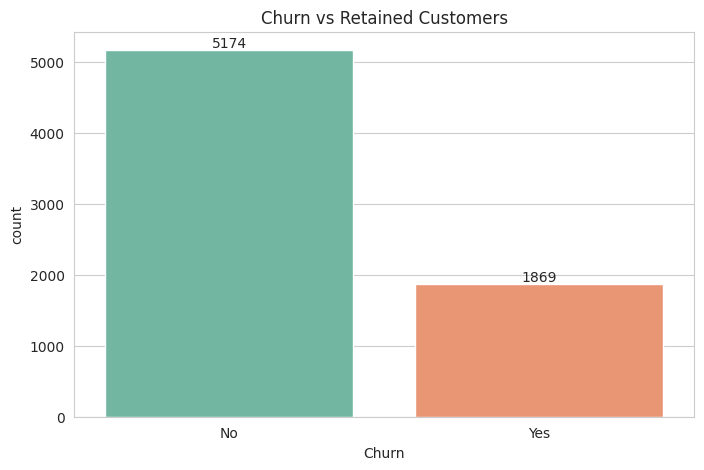

In [8]:
target_counts = churn_raw["Churn"].value_counts(normalize=True) * 100
print(target_counts)

fig, ax = plt.subplots()
sns.countplot(data=churn_raw, x="Churn", palette="Set2", ax=ax)
ax.set_title("Churn vs Retained Customers")
for container in ax.containers:
    ax.bar_label(container)
plt.show()

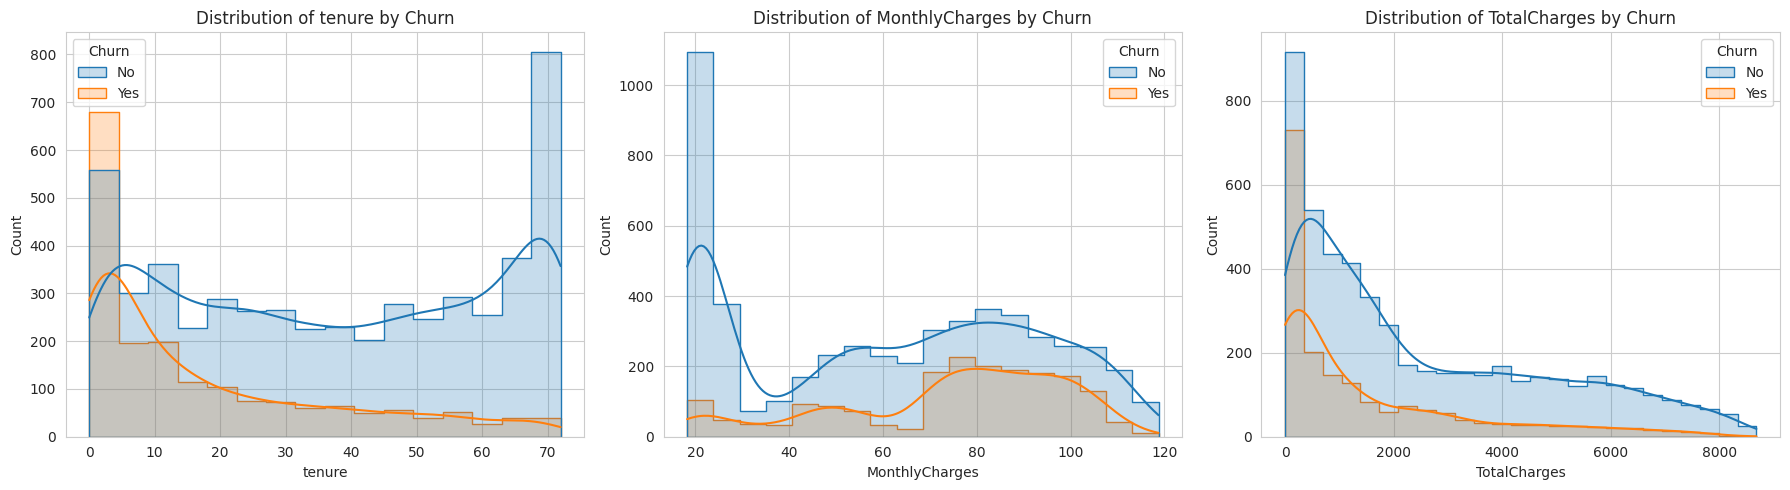

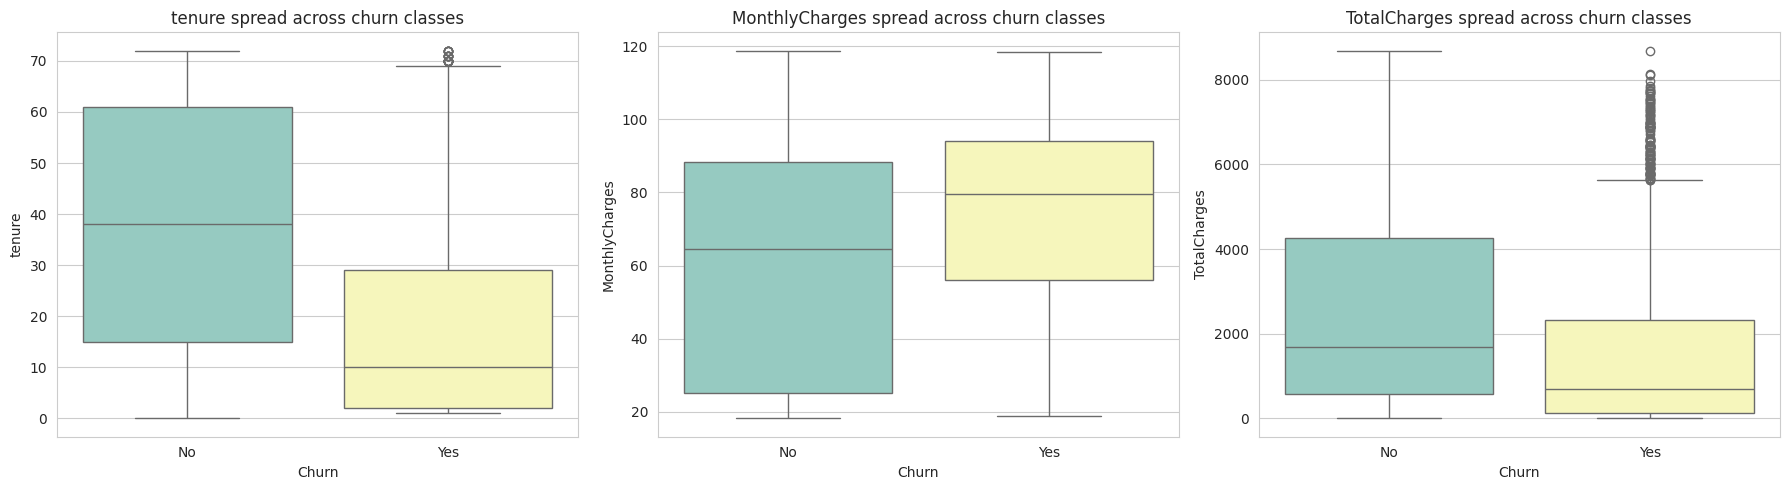

In [9]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for col, ax in zip(numeric_cols, axes):
    sns.histplot(data=churn_raw, x=col, hue="Churn", kde=True, element="step", ax=ax)
    ax.set_title(f"Distribution of {col} by Churn")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for col, ax in zip(numeric_cols, axes):
    sns.boxplot(data=churn_raw, x="Churn", y=col, palette="Set3", ax=ax)
    ax.set_title(f"{col} spread across churn classes")
plt.tight_layout()
plt.show()

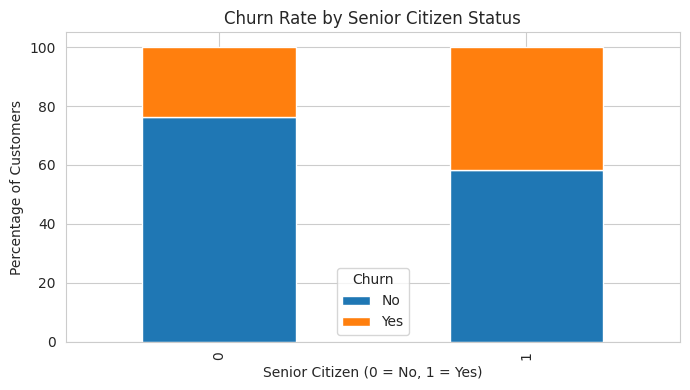

In [10]:
senior_churn = pd.crosstab(
    churn_raw["SeniorCitizen"],
    churn_raw["Churn"],
    normalize="index"
) * 100

senior_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 4)
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

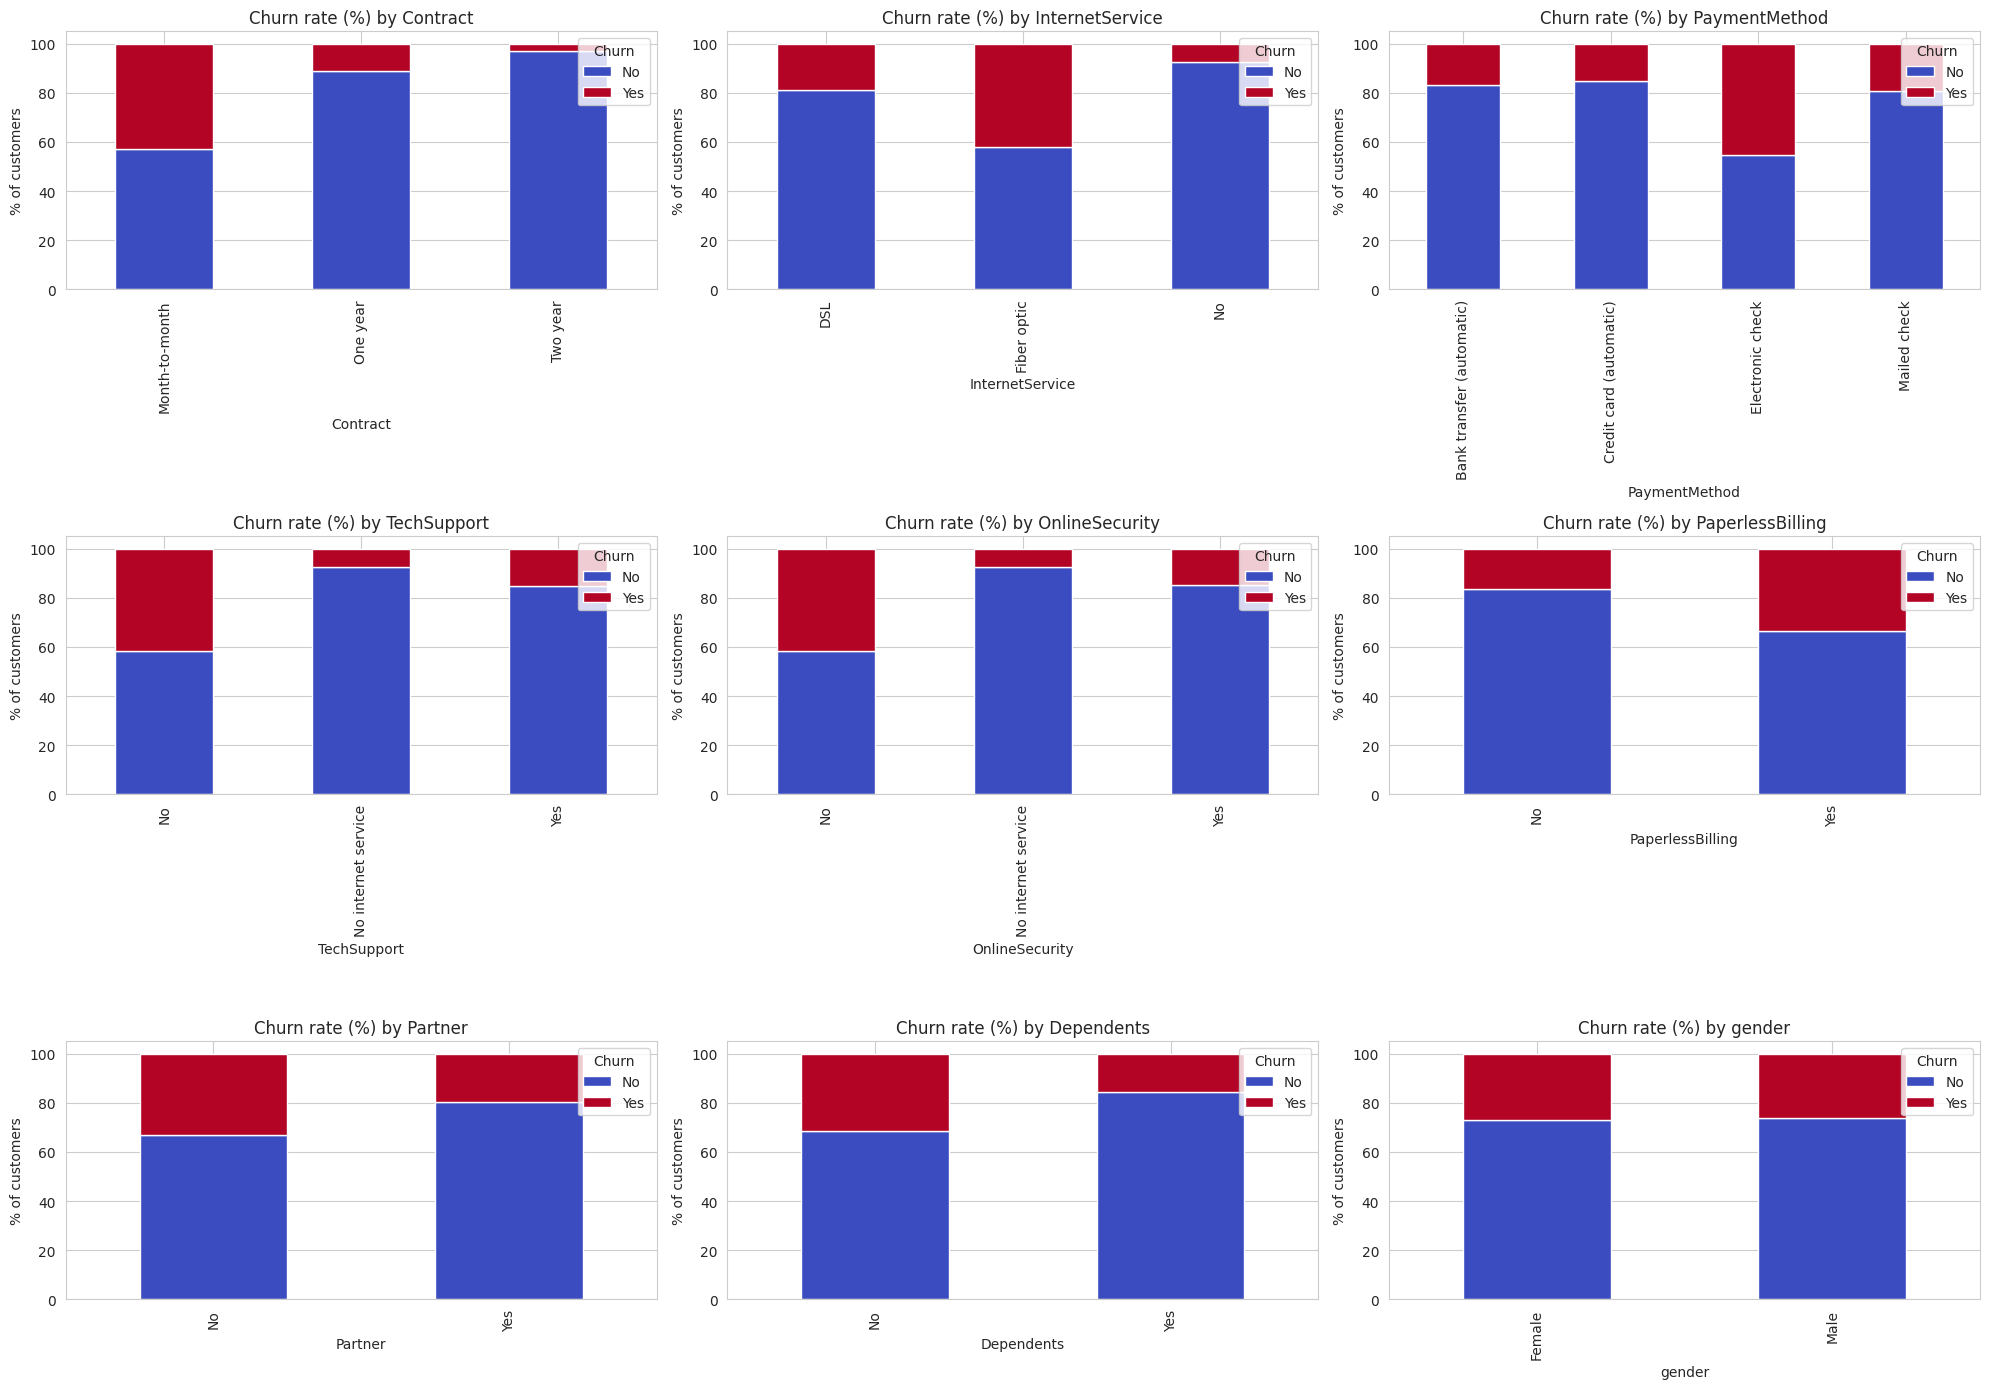

In [11]:
categorical_focus = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
    "Partner",
    "Dependents",
    "gender"
]

fig, axes = plt.subplots(3, 3, figsize=(20, 14))
axes = axes.flatten()
for col, ax in zip(categorical_focus, axes):
    cross_tab = pd.crosstab(churn_raw[col], churn_raw["Churn"], normalize="index") * 100
    cross_tab.plot(kind="bar", stacked=True, ax=ax, colormap="coolwarm")
    ax.set_title(f"Churn rate (%) by {col}")
    ax.set_ylabel("% of customers")
    ax.legend(title="Churn", loc="upper right")

plt.tight_layout()
plt.show()


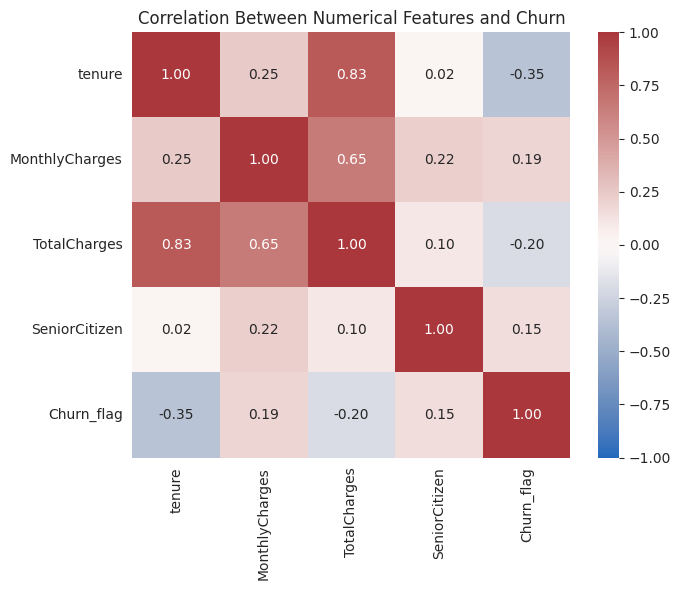

In [12]:
corr_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

corr_frame = churn_raw.copy()

corr_frame["Churn_flag"] = corr_frame["Churn"].map({
    "Yes": 1,
    "No": 0
})

corr_matrix = corr_frame[
    corr_cols + ["Churn_flag"]
].corr()

plt.figure(figsize=(7, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="vlag",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features and Churn")
plt.tight_layout()
plt.show()

## Task 02 - Preprocessing and model training

### Data preprocessing

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [14]:
churn_df = churn_raw.copy()

churn_df.drop(columns=["customerID"], inplace=True)
churn_df["Churn"] = churn_df["Churn"].map({"Yes": 1, "No": 0})

X_full = churn_df.drop(columns=["Churn"])
y_full = churn_df["Churn"]

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in X_full.columns if c not in numeric_features]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.20, random_state=RNG_SEED, stratify=y_full
)
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

numeric_pipeline = Pipeline(steps=[
    ("impute_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("impute_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

Train shape: (5634, 19) | Test shape: (1409, 19)


### Model buliding

In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)

model_registry = {}

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

print("Dummy Classifier Performance:")
print(classification_report(y_test, dummy_predictions,
                            target_names=["No Churn", "Churn"]))

Dummy Classifier Performance:
              precision    recall  f1-score   support

    No Churn       0.73      1.00      0.85      1035
       Churn       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



### K- Nearest Neighbour

In [18]:
knn_pipeline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", KNeighborsClassifier()),
])
knn_param_grid = {
    "clf__n_neighbors": [5, 7, 9, 11, 15, 21, 31],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["minkowski", "manhattan"],
}
knn_search = GridSearchCV(
    knn_pipeline, knn_param_grid, scoring="f1", cv=cv_strategy, n_jobs=-1, verbose=0
)
knn_search.fit(X_train, y_train)
model_registry["KNN"] = knn_search.best_estimator_
print("Best KNN params:", knn_search.best_params_)
print("Best KNN CV F1:", round(knn_search.best_score_, 4))

Best KNN params: {'clf__metric': 'manhattan', 'clf__n_neighbors': 31, 'clf__weights': 'uniform'}
Best KNN CV F1: 0.6069


### Logistic Regression

In [19]:
logreg_pipeline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RNG_SEED)),
])
logreg_param_grid = {
    "clf__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
    "clf__penalty": ["l2"],
    "clf__solver": ["lbfgs", "liblinear"],
}
logreg_search = GridSearchCV(
    logreg_pipeline, logreg_param_grid, scoring="f1", cv=cv_strategy, n_jobs=-1, verbose=0
)
logreg_search.fit(X_train, y_train)
model_registry["Logistic Regression"] = logreg_search.best_estimator_
print("Best LogReg params:", logreg_search.best_params_)
print("Best LogReg CV F1:", round(logreg_search.best_score_, 4))

Best LogReg params: {'clf__C': 0.05, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}
Best LogReg CV F1: 0.6304


### Random Forest

In [20]:
rf_pipeline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(class_weight="balanced", random_state=RNG_SEED)),
])
rf_param_distribution = {
    "clf__n_estimators": [200, 300, 400, 500, 600],
    "clf__max_depth": [None, 5, 10, 15, 20],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2"],
}
rf_search = RandomizedSearchCV(
    rf_pipeline,
    rf_param_distribution,
    n_iter=30,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    random_state=RNG_SEED,
    verbose=0,
)
rf_search.fit(X_train, y_train)
model_registry["Random Forest"] = rf_search.best_estimator_
print("Best RF params:", rf_search.best_params_)
print("Best RF CV F1:", round(rf_search.best_score_, 4))

Best RF params: {'clf__n_estimators': 200, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 4, 'clf__max_features': 'sqrt', 'clf__max_depth': 10}
Best RF CV F1: 0.6343


### Comparison

In [21]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, RocCurveDisplay
)

def summarize_performance(fitted_model, X_eval, y_eval, label):
    preds = fitted_model.predict(X_eval)
    probs = fitted_model.predict_proba(X_eval)[:, 1]
    row = {
        "Model": label,
        "Accuracy": accuracy_score(y_eval, preds),
        "Precision": precision_score(y_eval, preds),
        "Recall": recall_score(y_eval, preds),
        "F1-score": f1_score(y_eval, preds),
        "ROC-AUC": roc_auc_score(y_eval, probs),
    }
    return row, preds

results_table = []
predictions_store = {}

for model_name, fitted in model_registry.items():
    row, preds = summarize_performance(fitted, X_test, y_test, model_name)
    results_table.append(row)
    predictions_store[model_name] = preds
    print(f"{model_name}")
    print(classification_report(y_test, preds, target_names=["No Churn", "Churn"]))

comparison_df = pd.DataFrame(results_table).set_index("Model").round(4)
print("Model comparison summary:")
comparison_df

KNN
              precision    recall  f1-score   support

    No Churn       0.85      0.86      0.85      1035
       Churn       0.60      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

Random Forest
              precision    recall  f1-score   support

    No Churn       0.90      0.78      0.83      1035
       Churn       0.55      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77   

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN,0.7850,0.5983,0.5775,0.5878,0.8280
Logistic Regression,0.7424,0.5095,0.7861,0.6183,0.8401
Random Forest,0.7693,0.5478,0.7513,0.6336,0.8420


### Visualisation - Confusion matrix and ROC curves

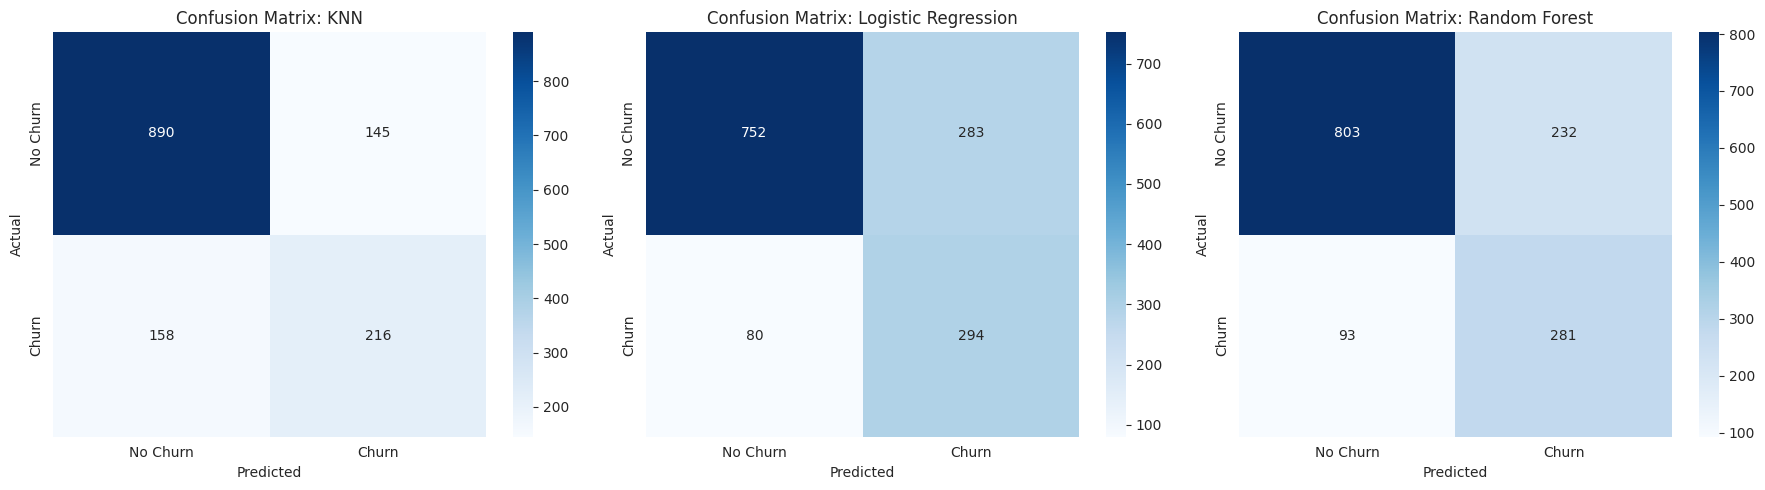

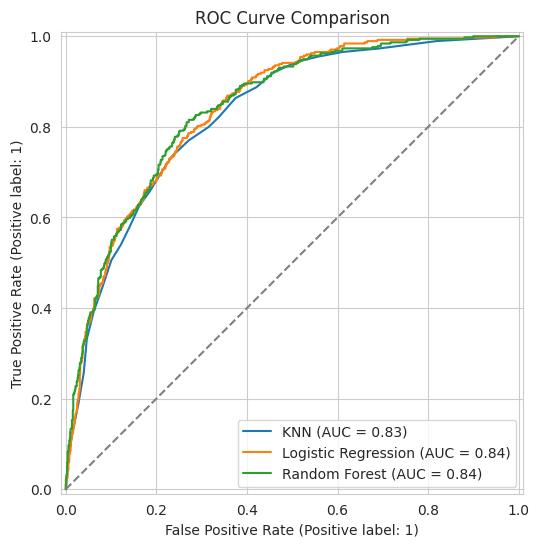

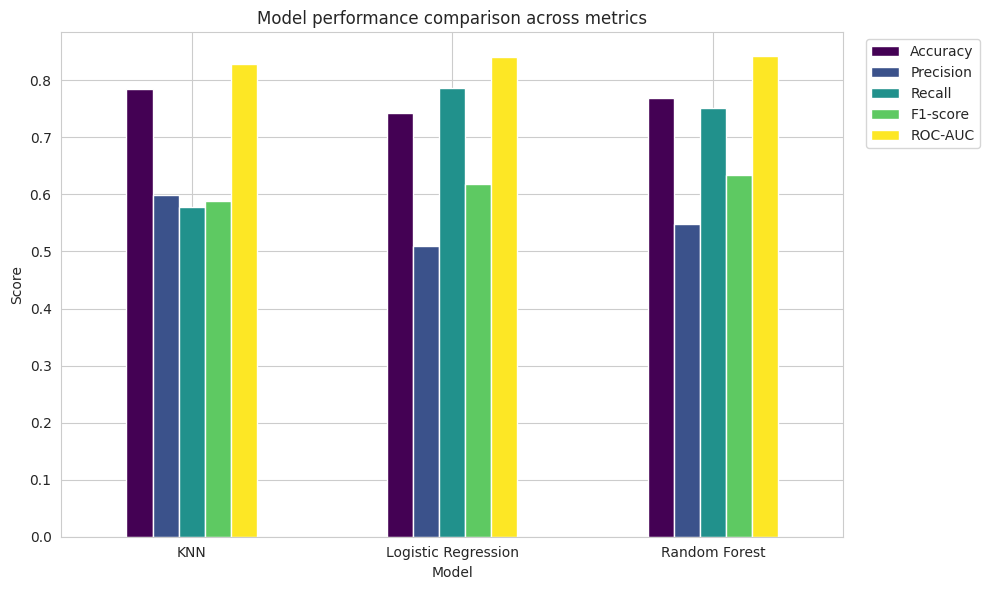

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (model_name, preds) in zip(axes, predictions_store.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
    ax.set_title(f"Confusion Matrix: {model_name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for model_name, fitted in model_registry.items():
    RocCurveDisplay.from_estimator(fitted, X_test, y_test, ax=ax, name=model_name)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_title("ROC Curve Comparison")
plt.show()

comparison_df.plot(kind="bar", figsize=(10, 6), colormap="viridis")
plt.title("Model performance comparison across metrics")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

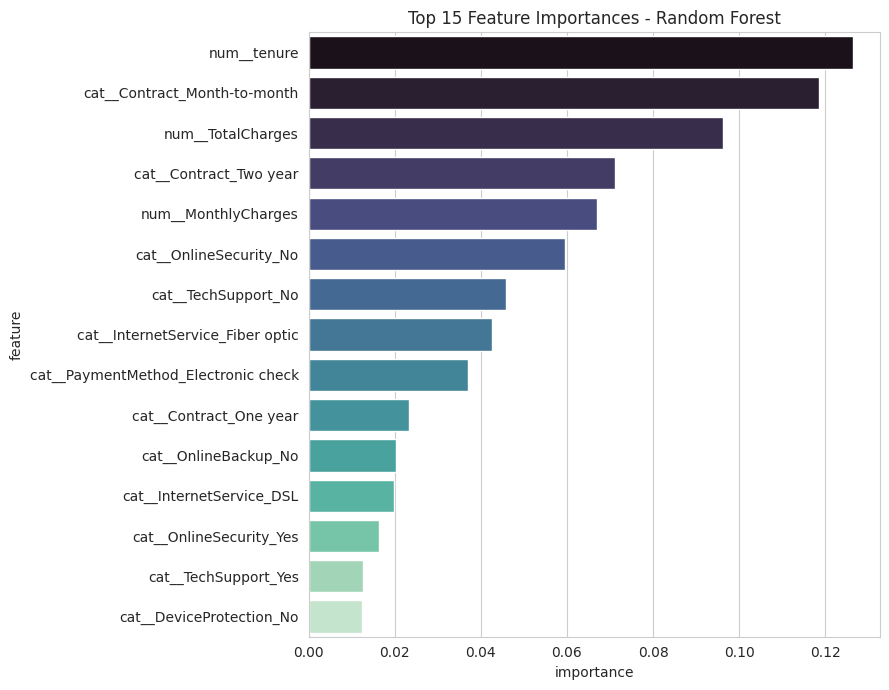

In [23]:
rf_best = model_registry["Random Forest"]
encoded_feature_names = rf_best.named_steps["prep"].get_feature_names_out()
importances = rf_best.named_steps["clf"].feature_importances_

importance_df = (
    pd.DataFrame({"feature": encoded_feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(15)
)

plt.figure(figsize=(9, 7))
sns.barplot(data=importance_df, x="importance", y="feature", palette="mako")
plt.title("Top 15 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

### Final results

In [24]:
import joblib

cv_f1_scores = {
    "KNN": knn_search.best_score_,
    "Logistic Regression": logreg_search.best_score_,
    "Random Forest": rf_search.best_score_
}

best_model_name = max(cv_f1_scores, key=cv_f1_scores.get)

best_model_obj = model_registry[best_model_name]

joblib.dump(best_model_obj, "best_churn_model.joblib")

print("Selected model:", best_model_name)
print("Cross-validation F1-score:", cv_f1_scores[best_model_name])


Selected model: Random Forest
Cross-validation F1-score: 0.6342539483906515
